<a href="https://colab.research.google.com/github/hammadhussain0811-crypto/aqi-forecasting/blob/main/AQI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#1.Connecting to Drive


In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#2.Save a permanent copy of the dataset

In [8]:
#import shutil
#shutil.copy('/content/city_day.csv', '/content/drive/MyDrive/city_day.csv')

#3.Loading the data

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('/content/drive/MyDrive/city_day.csv')
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values(['City', 'Date']).reset_index(drop=True)

print(df.shape)
df.head()

(29531, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   City        29531 non-null  object        
 1   Date        29531 non-null  datetime64[ns]
 2   PM2.5       24933 non-null  float64       
 3   PM10        18391 non-null  float64       
 4   NO          25949 non-null  float64       
 5   NO2         25946 non-null  float64       
 6   NOx         25346 non-null  float64       
 7   NH3         19203 non-null  float64       
 8   CO          27472 non-null  float64       
 9   SO2         25677 non-null  float64       
 10  O3          25509 non-null  float64       
 11  Benzene     23908 non-null  float64       
 12  Toluene     21490 non-null  float64       
 13  Xylene      11422 non-null  float64       
 14  AQI         24850 non-null  float64       
 15  AQI_Bucket  24850 non-null  object        
dtypes: datetime64[ns](1), 

#4.Keeping only our 4 cities

In [11]:
cities = ['Delhi', 'Lucknow', 'Bengaluru', 'Chennai']
data = df[df['City'].isin(cities)].copy()

print(data.shape)
print(data['City'].value_counts())

(8036, 16)
City
Bengaluru    2009
Chennai      2009
Delhi        2009
Lucknow      2009
Name: count, dtype: int64


#5.Checking missing values

In [12]:
cols = ['PM2.5', 'PM10', 'NO2', 'CO', 'SO2', 'O3', 'AQI']
data.groupby('City')[cols].apply(lambda x: x.isna().mean() * 100).round(1)

,PM2.5,PM10,NO2,CO,SO2,O3,AQI
City,,,,,,,
Bengaluru,7.3,17.9,0.3,0.5,0.3,7.2,4.9
Chennai,5.8,85.0,1.8,1.2,1.8,2.4,6.2
Delhi,0.1,3.8,0.1,0.0,5.5,4.2,0.5
Lucknow,5.1,100.0,1.2,1.4,3.2,1.3,5.8


#6.Plotting AQI over time for target cities

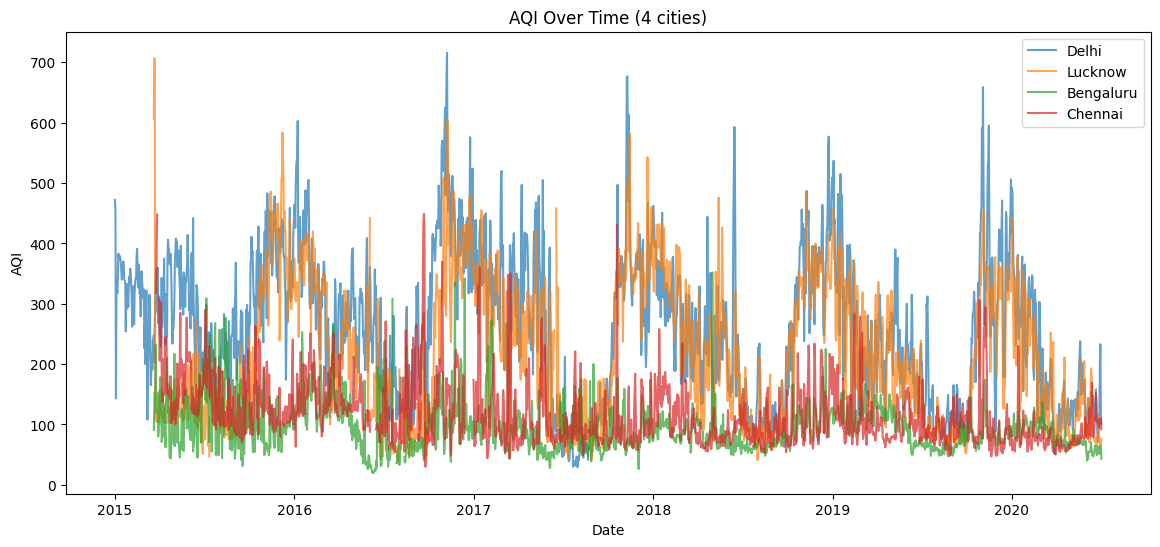

In [13]:
plt.figure(figsize=(14, 6))
for c in cities:
    t = data[data['City'] == c]
    plt.plot(t['Date'], t['AQI'], label=c, alpha=0.7)
plt.title('AQI Over Time (4 cities)')
plt.xlabel('Date')
plt.ylabel('AQI')
plt.legend()
plt.show()

In [14]:
for c in cities:
    s = data[data['City'] == c].set_index('Date')['AQI']
    is_na = s.isna()
    runs = is_na.groupby((~is_na).cumsum()).sum()
    print(c, '| first AQI date:', s.first_valid_index().date(), '| longest gap (days):', int(runs.max()))

Delhi | first AQI date: 2015-01-01 | longest gap (days): 4
Lucknow | first AQI date: 2015-03-21 | longest gap (days): 79
Bengaluru | first AQI date: 2015-03-21 | longest gap (days): 79
Chennai | first AQI date: 2015-03-24 | longest gap (days): 82


In [15]:
parts = []
for c in cities:
    t = data[data['City'] == c].sort_values('Date')
    first = t['AQI'].first_valid_index()
    parts.append(t.loc[first:])
data2 = pd.concat(parts).reset_index(drop=True)

for c in cities:
    s = data2[data2['City'] == c].set_index('Date')['AQI']
    is_na = s.isna()
    runs = is_na.groupby((~is_na).cumsum()).sum()
    print(c, '| rows:', len(s), '| start:', s.index.min().date(),
          '| longest gap:', int(runs.max()), '| missing AQI:', int(is_na.sum()))

Delhi | rows: 2009 | start: 2015-01-01 | longest gap: 4 | missing AQI: 10
Lucknow | rows: 1930 | start: 2015-03-21 | longest gap: 17 | missing AQI: 37
Bengaluru | rows: 1930 | start: 2015-03-21 | longest gap: 7 | missing AQI: 20
Chennai | rows: 1927 | start: 2015-03-24 | longest gap: 17 | missing AQI: 43


In [16]:
feat = ['PM2.5', 'NO2', 'CO', 'SO2', 'O3', 'AQI']   # PM10 dropped

filled = []
for c in cities:
    t = data2[data2['City'] == c].sort_values('Date').set_index('Date')
    t[feat] = t[feat].interpolate(method='time', limit=17, limit_area='inside')
    filled.append(t.reset_index())

data3 = pd.concat(filled, ignore_index=True)
data3 = data3[['City', 'Date'] + feat]

print(data3.groupby('City')[feat].apply(lambda x: x.isna().sum()))
data3.to_csv('/content/drive/MyDrive/data_4cities_filled.csv', index=False)

           PM2.5  NO2  CO  SO2  O3  AQI
City                                   
Bengaluru      0    0   0    0  17    0
Chennai        0    0   0    0   0    0
Delhi          0    0   0   75  64    0
Lucknow        0    0   0    0   0    0


In [17]:
pollutants = ['PM2.5', 'NO2', 'CO', 'SO2', 'O3']

data4 = data3.sort_values(['City', 'Date']).copy()
data4[pollutants] = data4.groupby('City')[pollutants].transform(lambda x: x.ffill().bfill())

print(data4.isna().sum())
print(data4.shape)
data4.to_csv('/content/drive/MyDrive/data_4cities_clean.csv', index=False)

City     0
Date     0
PM2.5    0
NO2      0
CO       0
SO2      0
O3       0
AQI      0
dtype: int64
(7796, 8)
